In [1]:
import numpy as np
from scipy.special import jv, jn_zeros
from scipy.sparse.linalg import eigsh, ArpackNoConvergence # , eigh_tridiagonal
from scipy.sparse import diags, identity
from scipy.interpolate import interp1d, CubicSpline
from scipy.integrate import quad
from joblib import Parallel, delayed
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

# Solución de la ecuación de difusión para un coeficiente $D(z)$ variable

## Parámetros físicos

In [2]:
##############################################################################
# 1. Parámetros Físicos (en nanómetros)
##############################################################################
# Conversión: 1 m = 1e9 nm.
D0 = 2e-9 * 1e18     # 2e-9 m²/s -> 2e9 nm²/s
D_s = D0*0.05        # 5% de D0
R = 1e-6 * 1e9       # 1e-6 m -> 1000 nm
z_c = 10             # 10 nm (altura crítica)
delta = 2            # 1 nm (ancho de transición)
lambda_param = 0.5   # en nm⁻¹
n_modes_radial = 50  # Cantidad de modos de R(ρ)
m_max = 50           # Cantidad de modos de Z(z)
N_z = 1000           # Número de nodos en z
alpha_grid = 3.0     # Aglomeramiento de nodos cerca de z=0
varkappa = 0         # nm/s
L = 100              # nm

## Malla adaptativa en $z$
Para el caso de la coordenada $z$, se opta por una malla que tenga una mayor concentración de nodos cerca de $z=0$ y que el espaciado entre estos aumente conforme $z>0$. Esto permite resolver los gradientes fuertes de $D(z)$ cerca de la superficie. Para hacer esto, se realiza una transformación hiperbólica para concentrar los nodos, como en la ecuación:
                
$$z_j=L\cdot \frac{\sinh{\left(\alpha_\mathrm{grid}\cdot\frac{j}{N_{z}-1}\right)}}{\sinh{\alpha_\mathrm{grid}}},\quad j\in\left[0,N_{z}-1\right]$$

Donde $\alpha_\mathrm{grid}\in\mathbb{N}$ es el parámetro de estiramiento, un factor que se encarga de controlar la densidad de nodos cerca de la superficie ($z\to0$), permitiendo una resolución espacial ajustada, $N_z$ es el número total de nodos y $L$ es la altura máxima en $z$.

De esta forma el espaciado entre nodos se calculará como:

$$h_j=z_j-z_{j-1},\,\forall\,j=1,2,\dots,N_z-1,\quad h_{j+1/2}=\frac{h_{j+1}+h_j}{2}$$

In [3]:
##############################################################################
# 2. Generación de la malla en z (nm)
##############################################################################
# j_vals = np.linspace(0, N_z, N_z)
j_vals1 = np.arange(int(N_z*0.65))
j_vals2 = np.arange(int(N_z*0.35))

z1 = z_c * np.sinh(alpha_grid * j_vals1 / (N_z*0.65 - 1)) / np.sinh(alpha_grid) # [0,z_c]
z2 = z_c + (L - z_c) * np.sinh(alpha_grid*j_vals2 / (N_z*0.35 - 1)) / np.sinh(alpha_grid) # [z_c,L]

z = np.concatenate((z1[:-2],z2))

## Perfil de difusión
Para evitar discontinuidades en $D(z)$, se introduce una transición suave como los es $\tanh{}$, que es diferenciable y suave, lo que evita inestabilidades numéricas:

$$D(z)=D_0\left[\left(1-\exp{\left(-\lambda z\right)}\right)\cdot\left(1-S(z)\right)+S(z)\right],\quad S(z)=\frac{1}{2}\left(1+\tanh{\left(\frac{z-z_c}{\delta}\right)}\right)$$

Donde $z_c$ es la altura donde comienza la transición y $\delta$ es el ancho de la transición y se puede definir como $\delta\ll z_c$ para un cambio rápido pero suave. La transición suave refleja gradientes físicamente realistas.

In [4]:
##############################################################################
# 3. Función de Difusión Global D(z) (z en nm)
##############################################################################
def D(z_val):
    """Perfil de difusión completo con z en nm.
       D(z) = D0 [exp(-λz)(1-S(z)) + S(z)] donde 
       S(z) = 0.5 [1 + tanh((z-z_c)/δ)].
    """
    S = 0.5 * (1 + np.tanh((z_val - z_c) / delta))
    return D0 * ((1-np.exp(-lambda_param * z_val)) * (1 - S) + S)
    # return D_s+(D0-D_s) * ((1-np.exp(-lambda_param * z_val)) * (1 - S) + S)

En la figura a continuación se muestra el perfil propuesto utilizando algunos parámetros seleccionados de forma arbitraria.

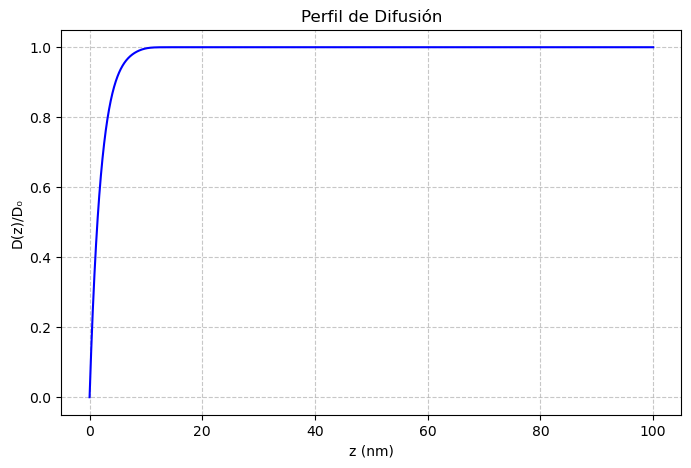

In [5]:
# Perfil de difusión
D_values = D(z)

plt.figure(figsize=(8,5))
plt.plot(z, D_values/D0, 'b-', lw=1.5)
plt.xlabel('z (nm)')
plt.ylabel('D(z)/D₀')
plt.title('Perfil de Difusión')
plt.grid(ls='--', alpha=0.7)
plt.savefig('figuras/Dz_profile.pdf', bbox_inches='tight')
plt.show()
plt.close()

## Solución radial
l término radial se puede tomar constante también, para lo cual se toma $-\alpha^2$, de forma tal que:
    
$$\frac{1}{\rho \mathcal{R}}\left[\frac{d\mathcal{R}}{d\rho}+\rho\frac{d^2\mathcal{R}}{d\rho^2}\right]=-\alpha^2$$

Que al multiplicar por $\rho^2$ y simplificar, se obtiene una forma similar a la forma estándar de Bessel de orden cero:

$$\rho^2\frac{d^2\mathcal{R}}{d\rho^2}+\rho\frac{d\mathcal{R}}{d\rho}+\rho^2\alpha^2\mathcal{R}=0$$

Tomando un cambio de variable tal que $x=\alpha\rho$, $\frac{d\mathcal{R}}{d\rho}=\alpha\frac{d\mathcal{R}}{dx}$ y $\frac{d^2\mathcal{R}}{d\rho^2}=\alpha^2\frac{d^2\mathcal{R}}{dx^2}$, al reemplazar en la ecuación original:

$$\frac{x^2}{\alpha^2}\alpha^2\frac{d^2\mathcal{R}}{dx^2}+\frac{x}{\alpha}\alpha\frac{d\mathcal{R}}{dx}+\frac{x^2}{\alpha^2}\alpha^2\mathcal{R}=0$$

Lo que nos lleva a la forma estándar de Bessel de orden cero:

$$x^2\frac{d^2\mathcal{R}}{dx^2}+x\frac{d\mathcal{R}}{dx}+x^2\mathcal{R}=0$$

Esta ecuación tiene como solución una combinación de funciones de Bessel de primera y segunda categoría:

$$\mathcal{R}(x)=AJ_0(x)+BY_0(x)$$

Debido a que $Y_0(x)$ presenta una singularidad cuando $x\to0$, se toma que $B=0$, por lo que la solución estaría dada como:

$$\mathcal{R}(\rho)=AJ_0(\alpha\rho)$$

Al aplicar las condiciones de frontera $\mathcal{R}(\rho=R)=0$:

$$\mathcal{R}(R)=AJ_0(\alpha R)=0$$

En la función de Bessel de primera especie, los ceros están dados como $j_{0,n}$, por lo que se tendría que $\alpha_n=\frac{j_{0,n}}{R}$, lo que nos lleva a una serie en la cual cada modo $n$ corresponde a un valor propio $\alpha_n$:

$$\mathcal{R}_n(\rho)=A_nJ_0\left(\frac{j_{0,n}}{R}\rho\right)$$

De tal forma que la solución para la parte radial está dada por la serie de Fourier-Bessel de la ecuación:

$$\mathcal{R}(\rho)=\sum_{n=1}^\infty A_nJ_0\left(\frac{j_{0,n}}{R}\rho\right)$$

El $A_n$ se integrará con los valores de $T_0$ de la solución temporal y los coeficientes de expansión axiales.

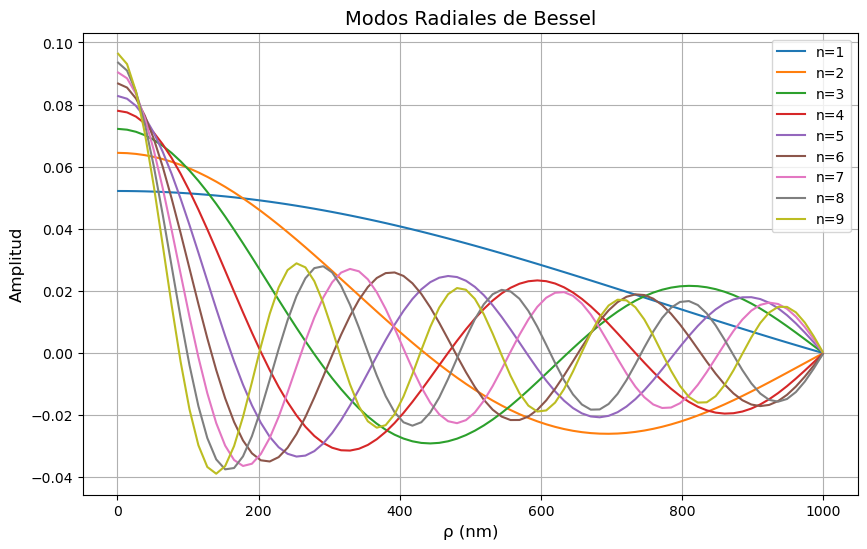

In [6]:
##############################################################################
# 4. Solución Radial R(ρ)
##############################################################################
# Cálculo de modos radiales
alpha_zeros = jn_zeros(0, n_modes_radial)
alpha_n = alpha_zeros / R  # Vector de α_n
rho_vals = np.linspace(0.001 * R, 0.999 * R, 80)  # 80 puntos en ρ

# Normalización de modos radiales
R_norms = np.sqrt((R**2 / 2) * jv(1, alpha_zeros)**2)  # ∫₀ᴿ J₀²(αₙρ) ρ dρ = R² J₁²(j₀ₙ)/2

# Evaluar funciones radiales normalizadas en rho_plot
J0_values = np.array([jv(0, alpha_n[n] * rho_vals) / np.sqrt(R_norms[n]) 
                     for n in range(n_modes_radial)])

# Graficar modos radiales
plt.figure(figsize=(10, 6))
for n in range(min(9, n_modes_radial)):
    plt.plot(rho_vals, J0_values[n], label=f"n={n+1}", linewidth=1.5)

plt.xlabel("ρ (nm)", fontsize=12)
plt.ylabel("Amplitud", fontsize=12)
plt.title("Modos Radiales de Bessel", fontsize=14)
plt.legend()
plt.grid(True)
plt.savefig("figuras/modos_radiales.pdf", bbox_inches="tight")
plt.show()
plt.close()

## Solución axial

En el caso del término axial se puede discretizar utilizando una diferencia hacia adelante para la primera derivada de $Z$:

$$\left.\frac{dZ}{dz}\right\vert_{z_j}\approx\frac{Z_{j+1}-Z_j}{h_{j+1}}$$

Mientras que para la segunda derivada:

$$\left.\frac{d}{dz}\left(D(z)\frac{dZ}{dz}\right)\right\vert_{z_j}\approx\frac{D_{j+\frac{1}{2}}\frac{Z_{j+1}+Z_j}{h_{j+1}}-D_{j-\frac{1}{2}}\frac{Z_j-Z_{j-1}}{h_j}}{h_{j+\frac{1}{2}}}$$

Donde $D_{j+\frac{1}{2}}=\frac{D(z_{j+1})-D(z_j)}{2}$. De esta forma la ecuación discretizada para los nodos internos, luego de sustituir y simplificar queda como:

$$\frac{D_{j+\frac{1}{2}}\left(Z_{j+1}-Z_j\right)}{h_{j+1}^2}-\frac{D_{j-\frac{1}{2}}\left(Z_j-Z_{j-1}\right)}{h_j^2}+\left(\Lambda^2-\alpha^2D_j\right)Z_j=0,\,\forall\,j=1,2,\dots,N_z-2$$
            
### Condiciones de contorno

#### Superficie ($z=0,\,j=0$)

En la superficie tenemos la condición de Robin, por lo que se puede proceder aproximando la derivada en $j=0$:

$$\left.\frac{dZ}{dz}\right\vert_{z_0}\approx\frac{Z_1-Z_{-1}}{2h_1}$$

Por lo que sustituyendo:

$$D_0\frac{Z_1-Z_{-1}}{2h_0}+\kappa Z_0=0\Rightarrow Z_{-1}=Z_1+\frac{2h_0\kappa}{D_0}Z_0$$

#### Borde superior $(z=L,\,j=N_z-1)$

En el borde superior tenemos una condición de Neumann de la ecuación, que al ser aproximada en $j=N_z-1$ queda de la forma:

$$\left.\frac{dZ}{dz}\right\vert_{z_{N_z-1}}\approx \frac{Z_{N_z-1}-Z_{N_z-2}}{h_{N_z-1}}$$

Y al sustituir en la condición:

$$\frac{Z_{N_z-1}-Z_{N_z-2}}{h_{N_z-1}}=0\Rightarrow Z_{N_z-1}=Z_{N_z-2}$$

### Ensamblaje de la matriz del sistema}

El sistema $AZ=\Lambda^2Z$ es un sistema de matriz tridiagonal y simétrica, se puede observar tras desarrollar y agrupar los productos de la ecuación:

$$-\frac{D_{j+\frac{1}{2}}}{h_j^2}Z_{j+1}+\left(\frac{D_{j-\frac{1}{2}}}{h_{j-1}^2}+\frac{D_{j+\frac{1}{2}}}{h_j^2}+\alpha^2D_j\right)Z_j-\frac{D_{j-\frac{1}{2}}}{h_{j-1}^2}Z_{j-1}=\Lambda^2Z_j$$
            
La matriz, al tratarse de un problema de Sturm-Liouville, debe ser simétrica:
$$
A=
\begin{pmatrix}
    a_0 & b_0 & 0 & \dots & 0 \\
    b_1 & a_1 & b_1 & \dots & 0 \\
    0 & \ddots & \ddots & \ddots & 0 \\
    0 & \dots & b_{N_z-2} & a_{N_z-2} & b_{N_z-2} \\
    0 & \dots & 0 & b_{N_z-1} & a_{N_z-1} \\
\end{pmatrix}
$$

Las diagonales estarán construidas como:

$$a_j=\frac{D_{j-\frac{1}{2}}}{h_{j-1}^2}+\frac{D_{j+\frac{1}{2}}}{h_j^2}+\alpha^2D_j$$

y 

$$b_j=-\frac{D_{j+\frac{1}{2}}}{h_j^2}$$

La diagonal principal contiene el término $\alpha^2D_j$, lo cual incorpora al modo radial dentro de la diagonal, lo que permite que los autovalores calculados no sean solamente los $\beta_m$, sino que más bien los $\Lambda_{n,m}$, de igual forma se incluye en la condición de contorno para $z=0$, como se observa en:

$$a_0 = \frac{2D_0}{h_0^2} - \frac{2\kappa}{h_0} + \alpha^2 D_0,\quad b_0 = -\frac{2D_0}{h_0^2}$$
            
Y las condiciones de Neumann quedan como:

$$a_{N_z-1} = \frac{D_L}{h_L^2} + \alpha^2 D_L,\quad b_{N_z-2} = -\frac{D_L}{h_L^2}$$

[Parallel(n_jobs=4)]: Using backend LokyBackend with 4 concurrent workers.
[Parallel(n_jobs=4)]: Done  42 tasks      | elapsed:  2.4min
[Parallel(n_jobs=4)]: Done  50 out of  50 | elapsed:  2.6min finished


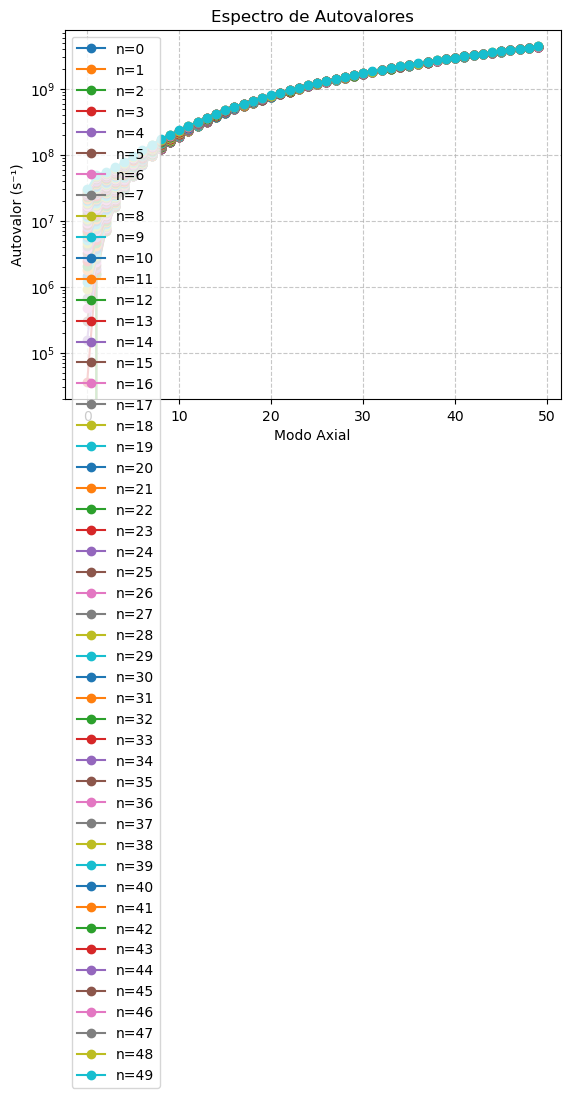

In [7]:
##############################################################################
# 5. Solución Axial Z(z)
##############################################################################
def build_system(n):
    """
    Construye la matriz simétrica A para el modo radial n.
    
    Args:
        n (int): Índice del modo radial.
        
    Returns:
        A (csr_matrix): Matriz simétrica tridiagonal.
    """
    try:
        alpha = alpha_n[n]
        h = np.diff(z)
        N = len(z)
        main_diag = np.zeros(N)
        upper_diag = np.zeros(N-1)
        lower_diag = np.zeros(N-1)

        # ---------------------------------------------------------------
        # 1. Índices internos (j=1 a N-2)
        # ---------------------------------------------------------------
        j_internos = np.arange(1, N-1)  # j=1, 2, ..., N-2
        j_prev = j_internos - 1         # j-1 = 0, 1, ..., N-3
        j_next = j_internos + 1         # j+1 = 2, 3, ..., N-1
    
        # ---------------------------------------------------------------
        # 2. Cálculo de coeficientes (vectorizado)
        # ---------------------------------------------------------------
        # Promedios armónicos de D en interfases
        D_prev = 2 * D_values[j_internos] * D_values[j_prev] / (D_values[j_internos] + D_values[j_prev] + 1e-30)  # D_{j-1/2}
        D_next = 2 * D_values[j_internos] * D_values[j_next] / (D_values[j_internos] + D_values[j_next] + 1e-30)  # D_{j+1/2}
        
        # Espaciados promedio
        h_avg_prev = 0.5 * (h[j_prev] + h[j_internos-1])  # h_avg para D_{j-1/2}
        h_avg_next = 0.5 * (h[j_internos] + h[j_next-1])  # h_avg para D_{j+1/2}
    
        # Términos de la matriz (simétricos)
        main_diag[j_internos] = (D_prev/(h[j_prev] * h_avg_prev)) + (D_next/(h[j_internos] * h_avg_next)) + alpha**2 * D_values[j_internos] # Incluye alpha_n
        upper_diag[j_internos] = -D_next / (h[j_internos] * h_avg_next)  # A[j, j+1]
        lower_diag[j_prev] = -D_prev / (h[j_prev] * h_avg_prev)          # A[j, j-1]
    
        # ---------------------------------------------------------------
        # 3. Condiciones de frontera - Simétricas
        # ---------------------------------------------------------------
        # Robin en z=0 (DZ' + κZ = 0)
        h0 = h[0]
        D0 = D_values[0]
        main_diag[0] = (2 * D0) / (h0 ** 2) - (2 * varkappa) / h0 + alpha**2 * D0  # Diagonal principal
        upper_diag[0] = - (2 * D0) / (h0 ** 2)  # Término superior
        lower_diag[0] = upper_diag[0]  # Simetría: A[0,1] = A[1,0]
    
        # Neumann en z=L (Z' = 0)
        hL = h[-1]
        DL = D_values[-1]
        main_diag[-1] = DL / hL**2 + alpha**2 * DL  # Diagonal principal
        lower_diag[-1] = - DL / hL**2  # Término inferior
        upper_diag[-1] = lower_diag[-1]  # Simetría: A[-1,-2] = A[-2,-1]
    
        # ---------------------------------------------------------------
        # 4. Ensamblar matriz tridiagonal simétrica
        # ---------------------------------------------------------------
        A = diags(
            diagonals=[main_diag, upper_diag, lower_diag],
            offsets=[0, 1, -1],
            shape=(N, N),
            format='csr'
        ) + 1e-10 * identity(N)
        eigenvalues, eigenvectors = eigsh(A, k=m_max, which='SM', tol=1e-6, maxiter=15000)
        # eigenvalues, eigenvectors = eigh_tridiagonal(main_diag, upper_diag, select='i', select_range=(0, m_max-1),eigvals_only=False)
        return (n, (eigenvalues, eigenvectors))
    except ArpackNoConvergence:
        print(f"Advertencia: Modo axial para n={n} no convergió. Usando ceros.")
        return (n, (np.zeros(m_max), np.zeros((N, m_max))))

axial_results = Parallel(n_jobs=4, verbose=1)(delayed(build_system)(n) for n in range(n_modes_radial))
eigenvalues_ax = {}
eigenvectors_ax = {}
for n, (evals, evecs) in sorted(axial_results, key=lambda x: x[0]):
    eigenvalues_ax[n] = evals
    eigenvectors_ax[n] = evecs

# Graficar espectro de autovalores
for n in range(n_modes_radial):
    evals = eigenvalues_ax[n]
    plt.semilogy(evals, 'o-', label=f'n={n}')
plt.xlabel('Modo Axial')
plt.ylabel('Autovalor (s⁻¹)')
plt.title('Espectro de Autovalores')
plt.legend()
plt.grid(ls='--', alpha=0.7)
plt.savefig('figuras/eigenvalues.pdf', bbox_inches='tight')
plt.show()
plt.close()

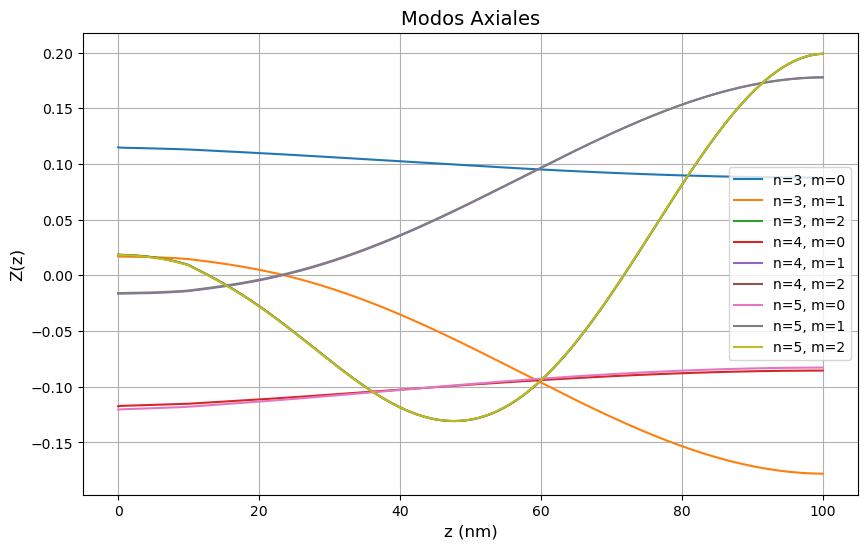

In [8]:
 # Normalizar los modos axiales en z
for n in range(n_modes_radial):
    for m in range(m_max):
        # norm = np.sqrt(np.trapz(eigenvectors_ax[n][:, m]**2, z))
        norm = np.sqrt(np.trapz(eigenvectors_ax[n][:, m]**2, z))
        if norm != 0:
            eigenvectors_ax[n][:, m] /= norm

# Graficar algunos modos axiales
plt.figure(figsize=(10,6))
for n in range(3,6): # range(min(3, n_modes_radial)):
    for m in range(min(3, m_max)):
        plt.plot(z, eigenvectors_ax[n][:, m], label=f"n={n}, m={m}", linewidth=1.5)
plt.xlabel("z (nm)", fontsize=12)
plt.ylabel("Z(z)", fontsize=12)
plt.title("Modos Axiales", fontsize=14)
plt.legend()
plt.grid(True)
plt.savefig("figuras/modos_axiales.pdf", bbox_inches="tight")
plt.show()
plt.close()

## Solución temporal

Se tiene que este debe ser constante, por lo que se toma $-\Lambda^2$, lo que permite plantear la ecuación:
    
$$\frac{1}{T}\frac{dT}{dt}=-\Lambda^2$$

De forma que al resolver la ecuación, se obtiene la solución:

$$T=\sum_{n=1}^{N_\rho}\sum_{m=1}^{M_z}T_{n,m}\exp{\left(-\Lambda_{n,m}^2t\right)}$$

Donde $\Lambda^2$ es un autovalor compuesto.

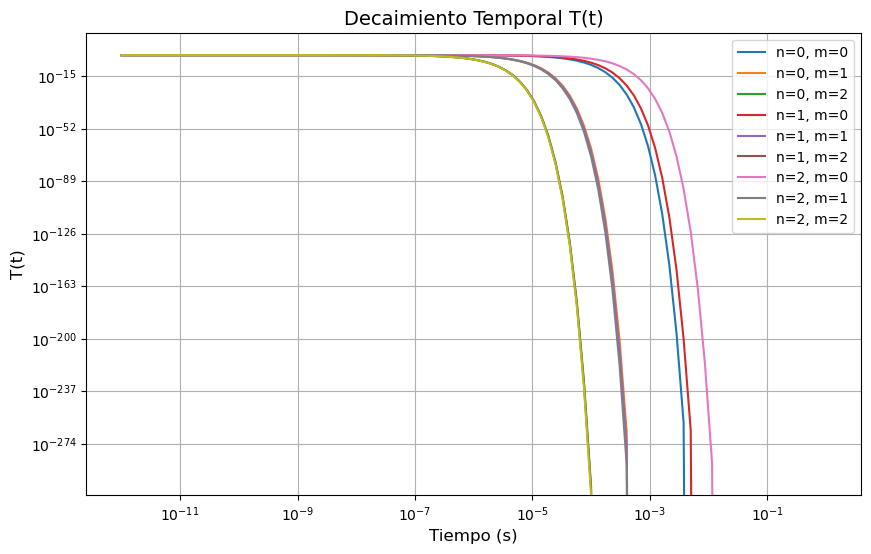

In [9]:
##############################################################################
# 6. Término Temporal T(t)
##############################################################################
# Ahora, para cada eigenvalor (de la parte axial) usaremos el valor absoluto
# para que T(t)=exp(-|λ| t) decaiga.
def T(t, lam):
    return np.exp(-np.abs(lam) * t)

# Graficamos T(t) para los modos del sistema axial

plt.figure(figsize=(10,6))
t_plot = np.logspace(-12, 0, 100)
for n in range(min(3,n_modes_radial)):
    for m in range(min(3, m_max)):
        lam = eigenvalues_ax[n][m]
        plt.loglog(t_plot, T(t_plot, lam), label=f"n={n}, m={m}", linewidth=1.5)
plt.xlabel("Tiempo (s)", fontsize=12)
plt.ylabel("T(t)", fontsize=12)
plt.title("Decaimiento Temporal T(t)", fontsize=14)
plt.legend()
plt.grid(True, which="both")
plt.savefig("figuras/T_t.pdf", bbox_inches="tight")
plt.show()
plt.close()

## Cálculo de los coeficientes $A_{n,m}$

Los coeficientes de expansión $A_{n,m}$ se determinan a partir de la proyección de la condición inicial sobre las funciones $\mathcal{R}(\rho)$ y $Z(z)$, utilizando la ortogonalidad de las funciones propias:

$$\frac{\langle P(\rho,z,0),J_0(\alpha_n\rho)Z_{n,m}(z)\rangle}{\mathcal{N}_n\mathcal{M}_{n,m}}$$

Lo que nos da como resultado la expresión:

$$A_{n,m} = \frac{J_0(\alpha_n \rho_0) Z_{n,m}(z_0)}{2\pi\mathcal{N}_n \mathcal{M}_{n,m}}$$

Donde:
- **La norma radial:** se obtiene a partir de la ortogonalidad de las funciones de Bessel, como se muestra en: $$\mathcal{N}_n = \sqrt{\int_0^R \rho J_0^2(\alpha_n \rho) d\rho}=\sqrt{ \frac{R^2}{2} J_1^2(j_{0,n})}$$
- **La norma axial:** No es necesario ponderar pues la forma de la ecuación de Sturm-Liouville indica que $r(x)=1$. La integral se calcula utilizando el método del trapecio. $$\mathcal{M}_{n,m} = sqrt{\int_0^L Z_{n,m}^2(z) dz}$$

In [10]:
##############################################################################
# 7. Cálculo de Coeficientes A_{nm}
##############################################################################
# Se asume que la condición inicial es:
#     P(ρ, z, 0) ∝ δ(ρ-ρ0) δ(z-z0) / (2πρ0)
# Con ρ0 = 750 nm y z0 = 10 nm.
rho0 = 750  # nm
z0 = 10     # nm

# Creamos funciones de interpolación para los modos axiales (resultado de la parte axial)
Z_interps = {}
for n in range(n_modes_radial):
    # Z_interps[n] = [interp1d(z, eigenvectors_ax[n][:, m], bounds_error=False, fill_value=0.0) for m in range(m_max)]
    Z_interps[n] = np.array([CubicSpline(z, eigenvectors_ax[n][:, m], extrapolate=False) for m in range(m_max)])
    
def compute_A_nm(n):    
    # Evalúa cada modo en z = 15 nm
    Z_m_z0 = np.array([Z_interps[n][m](z0) for m in range(m_max)])
    # Evalúa el modo radial en ρ0 = 750 nm
    J0_rho0 = jv(0, alpha_n[n] * rho0)
    return (J0_rho0/R_norms[n] * Z_m_z0) / (2 * np.pi)

A_nm = Parallel(n_jobs=4)(delayed(compute_A_nm)(n) for n in range(n_modes_radial))

## Integración de la solución completa

La densidad de probabilidad final se reconstruye como superposición de todos los modos de las ecuaciones temporal y radial con la solución que se obtiene de forma numérica para la parte axial. De esta forma, se construye la solución de la ecuación inicial con coeficiente de difusión variable.

$$P(\rho,z,t) = \sum_{n=1}^{N_\rho} \sum_{m=1}^{M_z} A_{n,m} J_0(\alpha_n \rho) Z_{n,m}(z) e^{-\Lambda^2_{n,m} t},$$

donde $N_\rho$ y $M_z$ se eligen para garantizar convergencia.

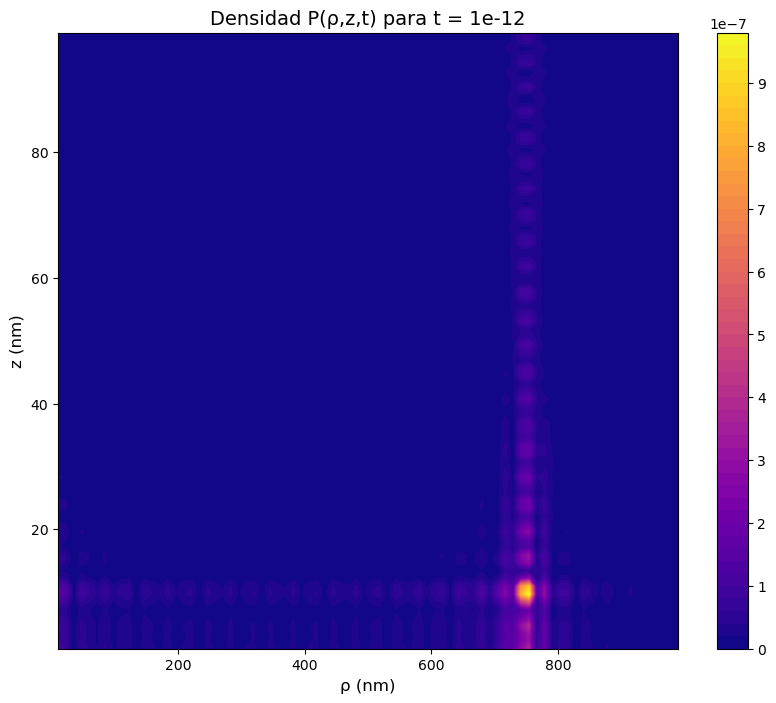

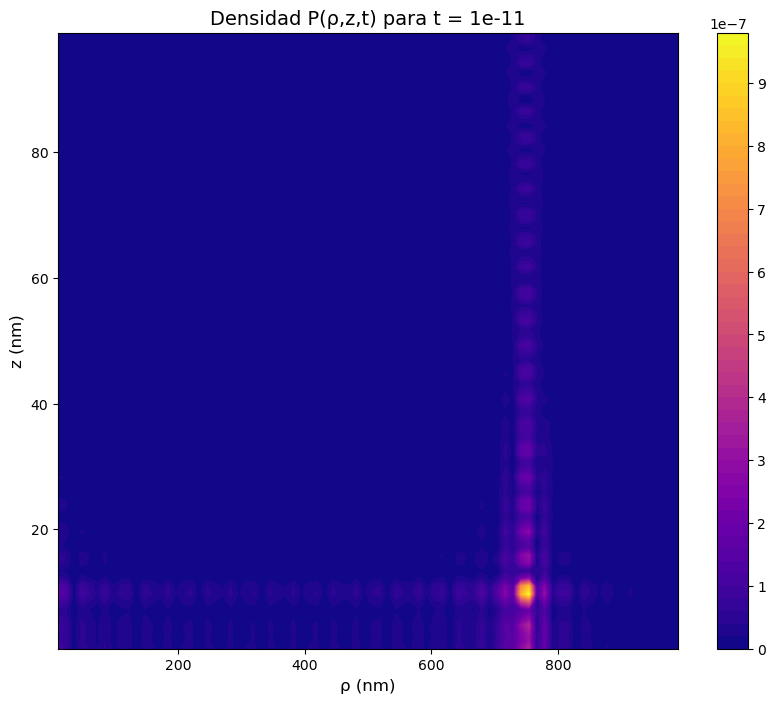

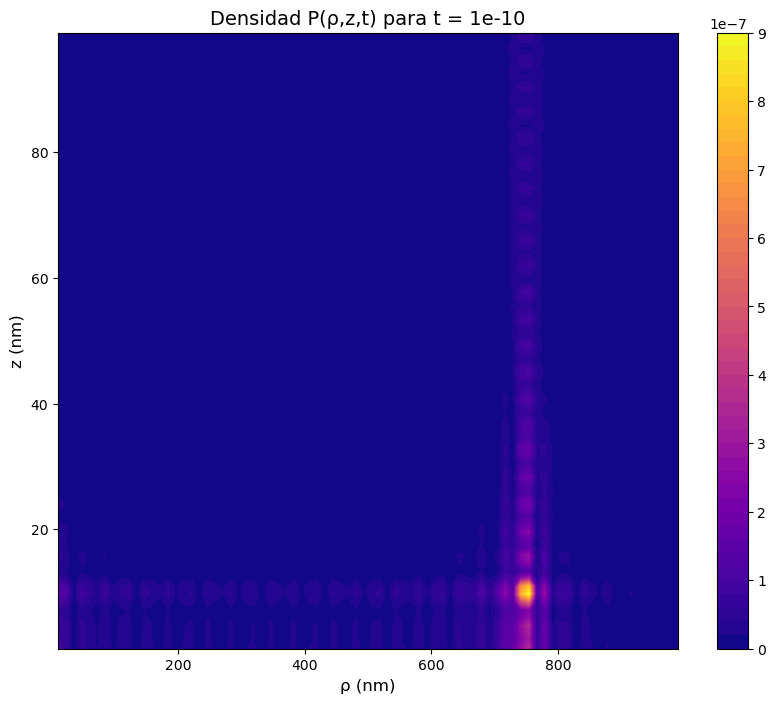

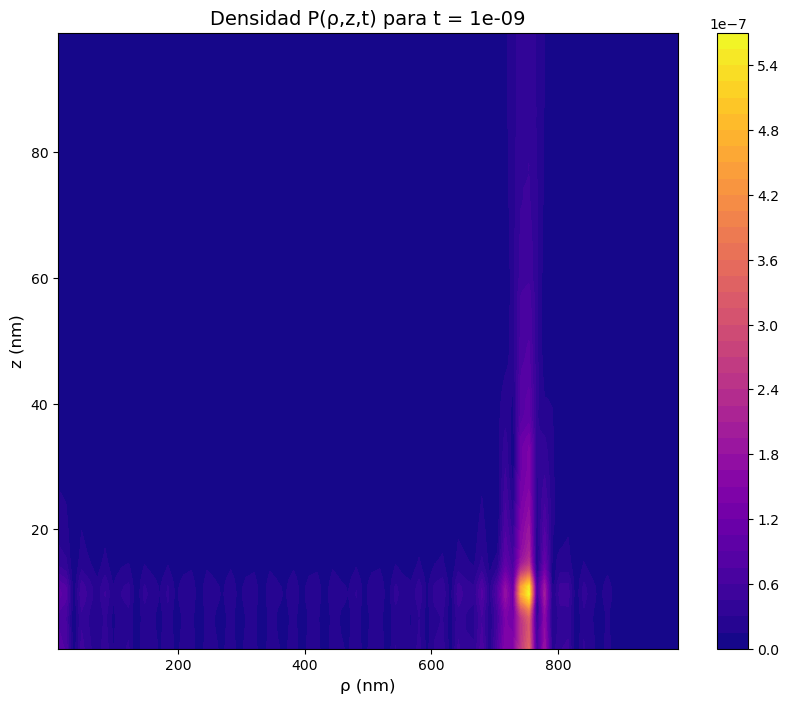

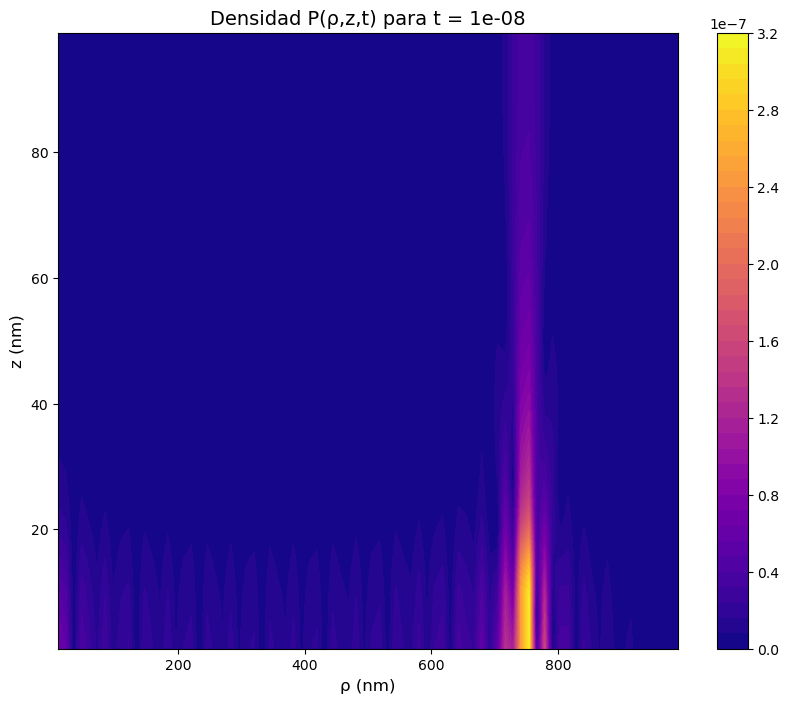

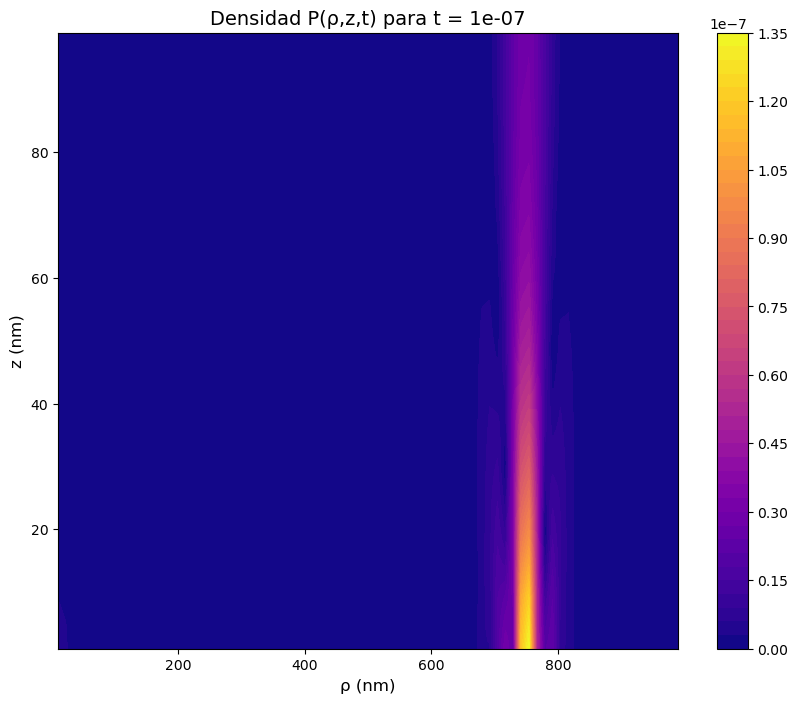

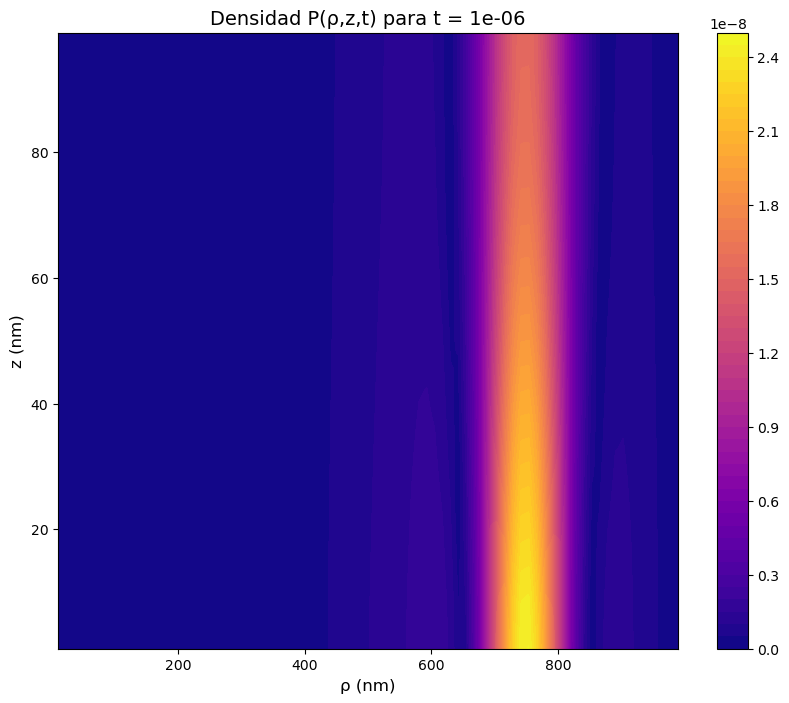

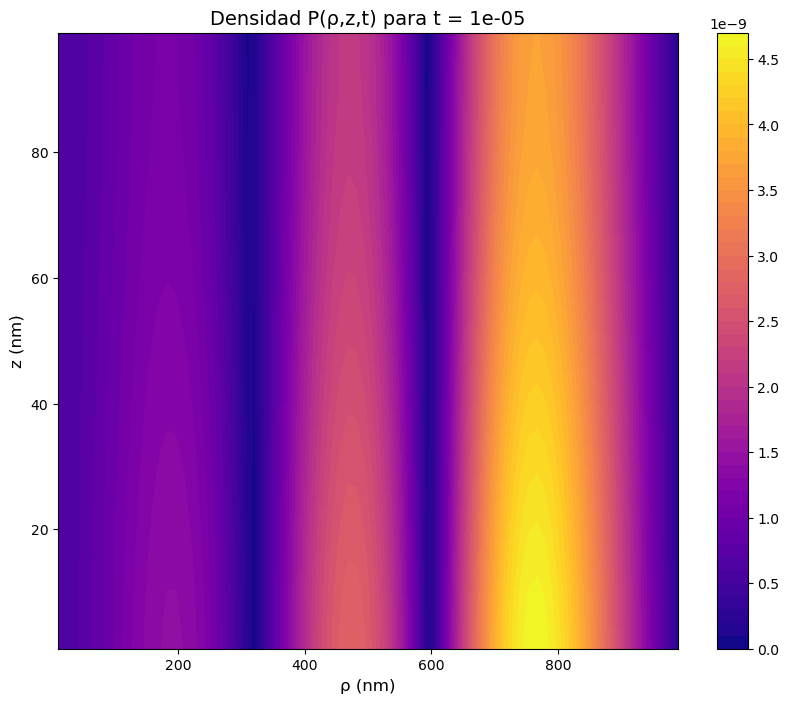

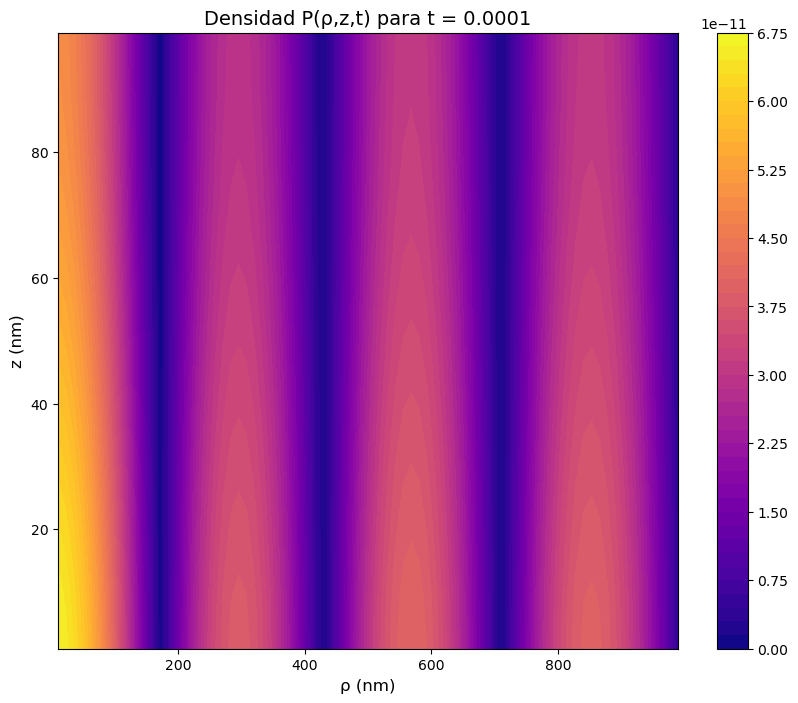

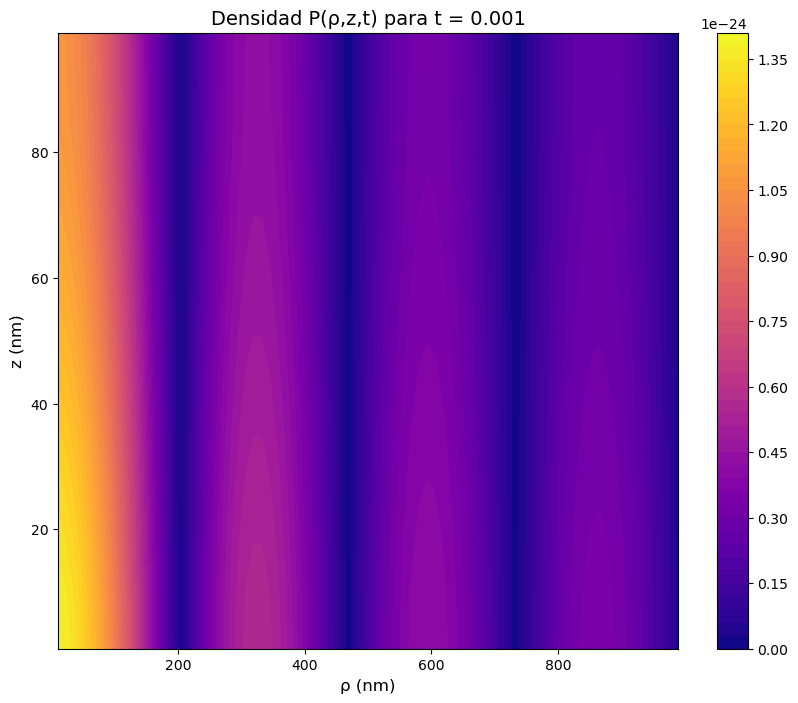

In [11]:
##############################################################################
# 8. Densidad de Probabilidad P(ρ,z,t)
##############################################################################
def compute_P(rho_vals, z_vals, t):
    P = np.zeros((len(z_vals), len(rho_vals)))
    # Para cada modo se usa T_{n,m}(t)= exp(-|λ_{n,m}|t)
    for i, rho in enumerate(rho_vals):
        J0_vals = jv(0, alpha_n * rho)
        for j, z_val in enumerate(z_vals):
            s = 0.0
            for n in range(n_modes_radial):
                for m in range(m_max):
                    Z_val = Z_interps[n][m](z_val)
                    T_val = T(t,eigenvalues_ax[n][m])
                    s += A_nm[n][m] * J0_vals[n]/R_norms[n] * Z_val * T_val
            P[j, i] = np.abs(s)
    return P

rho_vals = np.linspace(0.01 * R, 0.99 * R, 80)
z_vals = np.linspace(0.01*L, 0.99*L, 80)
for t_val in [1e-12,1e-11,1e-10,1e-9,1e-8,1e-7,1e-6,1e-5,1e-4,1e-3]:
    P_val = compute_P(rho_vals, z_vals, t=t_val)
    
    plt.figure(figsize=(10,8))
    plt.contourf(rho_vals, z_vals, P_val, 50, cmap="plasma")
    plt.xlabel("ρ (nm)", fontsize=12)
    plt.ylabel("z (nm)", fontsize=12)
    plt.title(f"Densidad P(ρ,z,t) para t = {t_val}", fontsize=14)
    plt.colorbar()
    plt.savefig(f"figuras/P_contour_{t_val}.pdf", bbox_inches="tight")
    plt.show()
    plt.close()

In [12]:
s = 0.0
for n in range(n_modes_radial):
    for m in range(m_max):
        s += (
            A_nm[n][m]
            * jv(0, alpha_n[n] * rho0) / R_norms[n]
            * Z_interps[n][m](z0)# *T(0.001,eigenvalues_ax[n][m])
        )
print("s =", s, " vs 1/(2πρ0) =", 1/(2*np.pi*rho0))

s = 1.1163787630171644e-06  vs 1/(2πρ0) = 0.0002122065907891938


## Función de correlación $G(t)$
    
La función de correlación del campo magnético detectado por el sensor NV se define mediante:

$$G(t)=\langle B(t)B(0)\rangle\propto\int d^3\textbf{r}\int d^3\textbf{r}_0 f(\textbf{r})f(\textbf{r}_0)P(\textbf{r,t}\vert\textbf{r}_0,0)$$

donde el factor de forma dipolar

$$f(\textbf{r})\propto\frac{Y_2^0(\Omega)}{\rvert\textbf{r}\lvert^3}\quad\text{con}\quad Y_2^0(\theta)=\frac{1}{4}\sqrt{\frac{5}{\pi}}\left(\cos^2{\theta}-1\right)$$

refleja la dependencia angular y radial de la interacción dipolar, siendo $\cos{\theta}=\frac{z}{\sqrt{\rho^2+z^2}}$ y $P(\textbf{r},t\vert\textbf{r}_0,0)$ es el propagador de difusión con $D(z)$ variable.

Por lo tanto, la integral se reduce a la expresión:

$$G(t)\propto\int_0^R\rho d\rho\int_0^Ldz\int_0^R\rho_0d\rho_0\int_0^Ldz_0\frac{\left(3z^2-\rho^2\right)}{\left(\rho^2+z^2\right)^{\frac{5}{2}}}\frac{\left(3z_0^2-\rho_0^2\right)}{\left(\rho_0^2+z_0^2\right)^\frac{5}{2}}P(\rho,z,t\vert\rho_0,z_0,0)$$

### Cálculo de la Función de Correlación $G(t)$
    
En esta sección describimos el procedimiento numérico empleado para evaluar la integral y obtener la función de correlación espectral.

Partiendo de la definición y del propagador separable 

$$P(\rho,z,t|\rho_0,z_0,0)=\sum_{n,m}A_{n,m}\,J_0(\alpha_n\rho)\,Z_{n,m}(z)\,e^{-\Lambda_{n,m}^2t}$$

la integral cuádruple se reduce a sumas discretas en $\rho,\,z,\,\rho_0,\,z_0$ sobre nodos y pesos apropiados.

### Selección y discretización de subdominios

La señal principal proviene de $\rho\in[0.1R,0.9R]$, $z\in[7,13]\,\mathrm{nm}$. Se utilizan $N_q$ nodos en cada dirección con regla trapezoidal no uniforme en $z$ (mismo mallado adaptativo) y uniforme en $\rho$.

#### Coordenada radial $\rho$

Para la parte radial usamos un mallado uniforme

$$\rho_{i} = 0.1\,R + (i-1)\,\Delta\rho,\quad \Delta\rho = \frac{0.9\,R-0.1\,R}{N_{\rho}-1},\quad i=1,\dots,N_{\rho}$$

#### Coordenada axial $z$

Dado que $D(z)$ varía muy rápido cerca de la superficie y que la región de mayor interés para $G(t)$ está en $[7,13]\,\mathrm{nm}$ (alrededor de $z_c$), se muestrean $N_{z}^{\rm quad}$ puntos siguiendo el mismo mallado hiperbólico ya definido para la solución axial.

$$z_j\in\left[7,13\right]\,\mathrm{nm}\Rightarrow j\in\left[0,N_z^\mathrm{quad}\right]$$
     
**Pesos de integración (regla del trapecio no uniforme)**
Para el eje axial definimos los pesos según la regla del trapecio con espaciado no uniforme:

$$\Delta z_m = z_{\rm nodes}[m+1]-z_{\rm nodes}[m], 
\quad
\omega_{z,m}= 
\begin{cases}
    \dfrac{\Delta z_1}{2}, & m=1,\\[6pt]
    \dfrac{\Delta z_{m-1} + \Delta z_m}{2}, & 1<m<N_{z}^{\rm quad},\\[6pt]
    \dfrac{\Delta z_{N_{z}^{\rm quad}-1}}{2}, & m=N_{z}^{\rm quad}. 
\end{cases}$$

De esta manera preservamos la densidad variable de nodos en $z$ sin perder exactitud ni aumentar arbitrariamente la resolución en $\rho$.

### Algoritmo de cálculo de $G(t)$
                
Definimos la función $G(t)$ de forma discreta como:

$$G(t)=\frac{5}{16\pi}\sum_{i=1}^{N_{\rho}^\mathrm{quad}}\sum_{m=1}^{N_{z}^{\rm quad}}f(\rho_{i},z_\mathrm{nodes}[m]) P(\rho_{i},z_\mathrm{nodes}[m],t)\rho_i\Delta\rho w_{z,m}$$

Donde:

$$f(\rho,z)=\frac{3z^2-\rho^2}{(\rho^2+z^2)^{5/2}},\quad P(\rho,z,t)=\sum_{n=1}^{N_{\rm rad}}\sum_{m=1}^{M}A_{n,m}\,J_{0}\!(\alpha_{n}\rho)\,Z_{n,m}(z)\,e^{-\lambda_{n,m}t}$$

Y, además, $\{A_{n,m}\}$, $\{\alpha_n\}$, $\{Z_{n,p}\}$, $\{\Lambda_{n,m}\}$ provienen de las soluciones radial y axial.

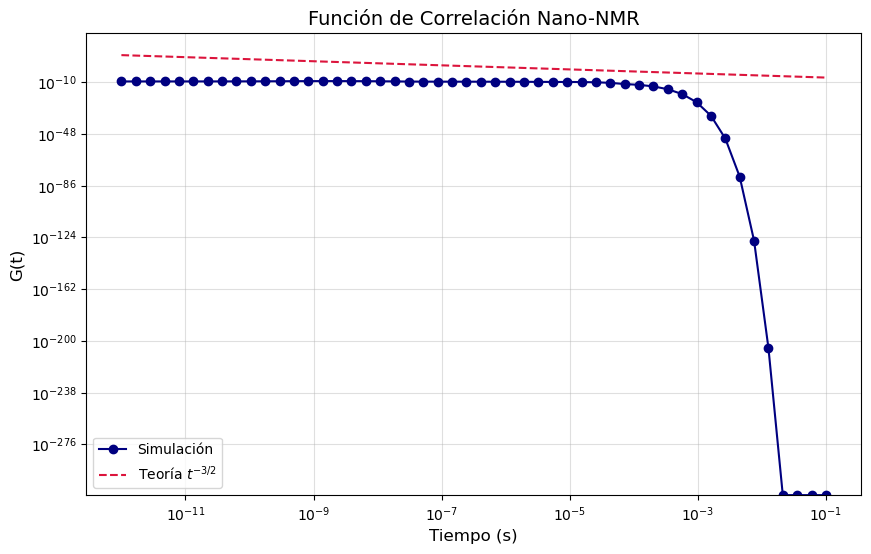

In [13]:
##############################################################################
# 9. Función de Correlación G(t)
##############################################################################
def compute_G(t, N_quad=40):
    # Dominios en nm: ρ en [0.3R, 0.7R] y z en [9,11] nm.
    z_min = 6
    z_max = 14
    j_nodes = np.linspace(z_min, z_max, N_quad)
    
    # Mallado no uniforme en z
    z_nodes = z_min + (z_max - z_min) * np.sinh(alpha_grid*j_nodes / (N_quad - 1))/np.sinh(alpha_grid) # [z_min,z_max]

    # calculamos pesos en z con la regla del trapecio no uniforme
    dz = np.diff(z_nodes)
    wz = np.empty_like(z_nodes)
    wz[0]    = dz[0]/2
    wz[-1]   = dz[-1]/2
    wz[1:-1] = 0.5*(dz[:-1]+dz[1:])

    # Mallado uniforme en rho
    rho_nodes = np.linspace(0.1 * R, 0.9 * R, N_quad)
    total = 0.0
    for rho in rho_nodes:
        J0_vals = jv(0, alpha_n * rho)
        for j,z_val in enumerate(z_nodes):
            f = (3 * z_val**2 - rho**2) / (rho**2 + z_val**2 + 1e-30)**2.5
            s = 0.0
            for n in range(n_modes_radial):
                for m in range(m_max):
                    Z_val = Z_interps[n][m](z_val)
                    T_val = np.exp(np.clip(-np.abs(eigenvalues_ax[n][m]) * t, -700, 700))
                    s += A_nm[n][m] * J0_vals[n] * Z_val * T_val
            total += np.abs(rho*f*s*wz[j])
    dr = (0.9 * R - 0.1 * R) / N_quad
    result = (5 / (16 * np.pi)) * (total * dr)
    return result

t_values = np.logspace(-12, -1, 50)
G_values = Parallel(n_jobs=4)(delayed(compute_G)(t) for t in t_values)

np.savetxt("data/G_vs_t.dat", np.c_[t_values, G_values], header="Tiempo(s) G(t)", fmt="%.3e")

plt.figure(figsize=(10,6))
plt.loglog(t_values, G_values, "o-", label="Simulación", color="navy", markersize=6, linewidth=1.5)
plt.plot(t_values, 1e-8 * t_values**-1.5, "--", label=r"Teoría $t^{-3/2}$", color="crimson", linewidth=1.5)
plt.xlabel("Tiempo (s)", fontsize=12)
plt.ylabel("G(t)", fontsize=12)
plt.title("Función de Correlación Nano-NMR", fontsize=14)
plt.legend()
plt.grid(which="both", alpha=0.4)
plt.savefig("figuras/correlacion_nanoNMR.pdf", bbox_inches="tight", dpi=300)
plt.show()
plt.close()